In [ ]:
# Cell 0 — install (Jupyter)
%pip -q install pandas numpy requests matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import time
import math
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional, Dict, Any, Tuple
from tqdm import tqdm

In [ ]:
def _parse_date_to_ms(s: str, end_of_day: bool = False) -> int:
    s = s.strip()
    # hỗ trợ "DD/MM/YYYY" hoặc "YYYY-MM-DD"
    if "/" in s:
        dt = pd.to_datetime(s, format="%d/%m/%Y")
    else:
        dt = pd.to_datetime(s, format="%Y-%m-%d")
    if end_of_day:
        dt = dt.replace(hour=23, minute=59, second=59)
    return int(dt.tz_localize("UTC").timestamp() * 1000)

def _interval_to_ms(interval: str) -> int:
    interval = interval.strip().lower()
    unit = interval[-1]
    val = int(interval[:-1])
    if unit == "m":
        return val * 60_000
    if unit == "h":
        return val * 3_600_000
    if unit == "d":
        return val * 86_400_000
    if unit == "w":
        return val * 7 * 86_400_000
    raise ValueError(f"Unsupported interval: {interval}")

def fetch_binance_klines_df(
    symbol: str,
    interval: str,
    start_date: str,
    end_date: str,
    market: str = "spot",            # "spot" or "futures"
    sleep_s: float = 0.2,
    limit: int = 1000,
    use_cache: bool = True,
    cache_dir: str = "data_cache"
) -> pd.DataFrame:
    symbol = symbol.upper()
    interval = interval.lower()
    market = market.lower()

    if market == "spot":
        base_url = "https://api.binance.com"
        path = "/api/v3/klines"
    elif market == "futures":
        base_url = "https://fapi.binance.com"
        path = "/fapi/v1/klines"
    else:
        raise ValueError("market must be 'spot' or 'futures'")

    os_path_safe = f"{symbol}_{interval}_{start_date.replace('/','-')}_{end_date.replace('/','-')}_{market}.csv"
    import os
    os.makedirs(cache_dir, exist_ok=True)
    cache_path = os.path.join(cache_dir, os_path_safe)

    if use_cache and os.path.exists(cache_path):
        df = pd.read_csv(cache_path)
        df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
        df = df.set_index("timestamp")
        return df.astype(float)

    start_ms = _parse_date_to_ms(start_date, end_of_day=False)
    end_ms = _parse_date_to_ms(end_date, end_of_day=True)
    step_ms = _interval_to_ms(interval)

    sess = requests.Session()
    all_rows = []

    pbar = tqdm(total=None, desc=f"📥 Crawling Binance OHLCV ({market})", unit="req")
    while start_ms < end_ms:
        params = {
            "symbol": symbol,
            "interval": interval,
            "startTime": start_ms,
            "endTime": end_ms,
            "limit": limit,
        }
        r = sess.get(base_url + path, params=params, timeout=30)
        if r.status_code != 200:
            raise RuntimeError(f"Binance API error {r.status_code}: {r.text}")

        data = r.json()
        if not data:
            break

        all_rows.extend(data)
        last_open = data[-1][0]
        start_ms = last_open + step_ms  # tránh trùng nến
        pbar.update(1)
        time.sleep(sleep_s)

        # nếu server trả ít hơn limit, thường là đã gần hết
        if len(data) < limit:
            break

    pbar.close()

    df = pd.DataFrame(all_rows, columns=[
        "timestamp","Open","High","Low","Close","Volume",
        "close_time","quote_asset_volume","num_trades",
        "taker_buy_base_volume","taker_buy_quote_volume","ignore"
    ])
    df = df[["timestamp","Open","High","Low","Close","Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df = df.set_index("timestamp").astype(float)

    if use_cache:
        df.reset_index().to_csv(cache_path, index=False)

    return df

# === RUN CRAWL ===
SYMBOL   = "ETHUSDT"
INTERVAL = "4h"
START    = "2024-01-01"
END      = "2026-01-21"
MARKET   = "spot"   # đổi sang "futures" nếu muốn

df = fetch_binance_klines_df(SYMBOL, INTERVAL, START, END, market=MARKET, use_cache=True)
print(f"✅ Loaded: {len(df)} bars | {df.index.min()} -> {df.index.max()} (UTC)")
df.head()


✅ Loaded: 4508 bars | 2024-01-01 00:00:00+00:00 -> 2026-01-21 04:00:00+00:00 (UTC)


,Open,High,Low,Close,Volume
timestamp,,,,,
2024-01-01 00:00:00+00:00,2281.87,2306.60,2271.00,2273.81,35739.3336
2024-01-01 04:00:00+00:00,2273.80,2287.88,2265.24,2284.67,28107.5133
2024-01-01 08:00:00+00:00,2284.68,2305.05,2280.00,2304.47,27894.1092
2024-01-01 12:00:00+00:00,2304.47,2318.34,2294.84,2314.70,32165.8522
2024-01-01 16:00:00+00:00,2314.69,2340.98,2306.48,2337.26,46802.2526


In [ ]:
def ema(series: pd.Series, span: int) -> pd.Series:
    return series.ewm(span=span, adjust=False).mean()

def atr(df: pd.DataFrame, period: int = 14) -> pd.Series:
    h, l, c = df["High"], df["Low"], df["Close"]
    pc = c.shift(1)
    tr = pd.concat([(h - l), (h - pc).abs(), (l - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1/period, adjust=False).mean()

def rsi(close: pd.Series, period: int = 14) -> pd.Series:
    d = close.diff()
    up = d.clip(lower=0)
    dn = (-d).clip(lower=0)
    ru = up.ewm(alpha=1/period, adjust=False).mean()
    rd = dn.ewm(alpha=1/period, adjust=False).mean()
    rs = ru / rd.replace(0, np.nan)
    out = 100 - 100 / (1 + rs)
    return out.fillna(50)

# === Params (đổi tùy ý) ===
KC_EMA = 20
ATR_P  = 14
KC_MUL = 1.5
RSI_P  = 14

atr_raw = atr(df, ATR_P)
kc_mid  = ema(df["Close"], KC_EMA)
kc_up   = kc_mid + KC_MUL * atr_raw
kc_dn   = kc_mid - KC_MUL * atr_raw
rsi_v   = rsi(df["Close"], RSI_P)

# Signal quyết định tại CLOSE[t], vào lệnh tại OPEN[t+1] -> backtest sẽ shift(1)
long_sig  = (df["Close"] > kc_up) & (rsi_v > 55)
short_sig = (df["Close"] < kc_dn) & (rsi_v < 45)
signal = long_sig.astype(int) - short_sig.astype(int)   # {+1,0,-1}

# ATR dùng để set TP/SL khi vào lệnh tại OPEN[t+1] => dùng ATR[t] (biết tại close[t])
atr_for_entry = atr_raw.copy()


In [ ]:
@dataclass
class BTConfig:
    initial_equity: float = 10_000.0
    fee_rate: float = 0.0004          # 4 bps/trade side (taker ~ 0.04% => 0.0004)
    slippage_bps: float = 1.0         # 1 bp slippage (bạn có thể tăng)
    leverage: float = 1.0
    risk_fraction: float = 0.01       # risk theo equity: 1%/trade (position sizing)
    max_pos_fraction: float = 1.0     # cap notional = equity*leverage*max_pos_fraction
    sl_first_if_both_hit: bool = True # nếu 1 bar chạm cả TP&SL -> chọn SL (conservative)
    max_hold_bars: Optional[int] = None

def _apply_slippage(price: float, side: int, is_entry: bool, bps: float) -> float:
    slip = bps / 10_000.0
    if side == 1:
        return price * (1 + slip) if is_entry else price * (1 - slip)
    else:
        return price * (1 - slip) if is_entry else price * (1 + slip)

def run_backtest_tp_sl_touch(
    df: pd.DataFrame,
    signal: pd.Series,
    atr_for_entry: pd.Series,
    tp_atr_mult: float = 1.5,
    sl_atr_mult: float = 1.0,
    cfg: BTConfig = BTConfig(),
) -> Tuple[pd.Series, pd.DataFrame, pd.Series]:
    sig_open = signal.shift(1).fillna(0).astype(int).values  # entry at open[t] using signal[t-1]

    o = df["Open"].values
    h = df["High"].values
    l = df["Low"].values
    c = df["Close"].values
    atrv = atr_for_entry.values

    cash = cfg.initial_equity
    pos = 0
    qty = 0.0
    entry = 0.0
    tp = 0.0
    sl = 0.0
    hold = 0
    entry_equity = 0.0

    equity_curve = np.empty(len(df), dtype=float)
    in_position  = np.zeros(len(df), dtype=int)
    trades = []

    for i in range(len(df)):
        if i == 0:
            equity_curve[i] = cash
            continue

        sig = int(sig_open[i])
        open_i, high_i, low_i, close_i = o[i], h[i], l[i], c[i]

        # (A) Reversal: nếu đang giữ mà signal đổi chiều -> đóng tại OPEN (không lookahead)
        if pos != 0 and sig != 0 and sig == -pos:
            exit_px = _apply_slippage(open_i, pos, is_entry=False, bps=cfg.slippage_bps)
            fee = cfg.fee_rate * abs(exit_px * qty)
            pnl = (exit_px - entry) * qty * pos - fee
            cash += pnl
            trades.append({
                "entry_time": df.index[i-1], "exit_time": df.index[i],
                "side": pos, "entry": entry, "exit": exit_px, "qty": qty,
                "pnl_net": pnl, "ret_on_eq": pnl / entry_equity if entry_equity > 0 else np.nan,
                "hold_bars": hold
            })
            pos, qty, entry, tp, sl, hold, entry_equity = 0, 0.0, 0.0, 0.0, 0.0, 0, 0.0

        # (B) Entry tại OPEN nếu đang flat
        if pos == 0 and sig != 0:
            atr_i = atrv[i-1]  # ATR biết tại close[i-1]
            if np.isfinite(atr_i) and atr_i > 0:
                pos = sig
                entry = _apply_slippage(open_i, pos, is_entry=True, bps=cfg.slippage_bps)

                sl = entry - pos * sl_atr_mult * atr_i
                tp = entry + pos * tp_atr_mult * atr_i

                stop_dist = abs(entry - sl)
                if stop_dist > 0:
                    risk_cap = cash * cfg.risk_fraction
                    qty = risk_cap / stop_dist

                    notional_cap = cash * cfg.leverage * cfg.max_pos_fraction
                    if qty * entry > notional_cap:
                        qty = notional_cap / entry

                    fee = cfg.fee_rate * abs(entry * qty)
                    cash -= fee
                    entry_equity = cash
                    hold = 0
                else:
                    pos = 0

        # (C) TP/SL touch fill trong bar (conservative nếu chạm cả 2)
        exited = False
        if pos != 0 and qty > 0:
            hold += 1
            hit_sl = (pos == 1 and low_i <= sl) or (pos == -1 and high_i >= sl)
            hit_tp = (pos == 1 and high_i >= tp) or (pos == -1 and low_i <= tp)

            if hit_sl or hit_tp:
                if hit_sl and hit_tp:
                    exit_level = sl if cfg.sl_first_if_both_hit else tp
                else:
                    exit_level = sl if hit_sl else tp

                exit_px = _apply_slippage(exit_level, pos, is_entry=False, bps=cfg.slippage_bps)
                fee = cfg.fee_rate * abs(exit_px * qty)
                pnl = (exit_px - entry) * qty * pos - fee
                cash += pnl
                trades.append({
                    "entry_time": df.index[i-1], "exit_time": df.index[i],
                    "side": pos, "entry": entry, "exit": exit_px, "qty": qty,
                    "pnl_net": pnl, "ret_on_eq": pnl / entry_equity if entry_equity > 0 else np.nan,
                    "hold_bars": hold
                })
                pos, qty, entry, tp, sl, hold, entry_equity = 0, 0.0, 0.0, 0.0, 0.0, 0, 0.0
                exited = True

            # (D) Max-hold exit tại CLOSE
            if (not exited) and (cfg.max_hold_bars is not None) and (hold >= cfg.max_hold_bars):
                exit_px = _apply_slippage(close_i, pos, is_entry=False, bps=cfg.slippage_bps)
                fee = cfg.fee_rate * abs(exit_px * qty)
                pnl = (exit_px - entry) * qty * pos - fee
                cash += pnl
                trades.append({
                    "entry_time": df.index[i-1], "exit_time": df.index[i],
                    "side": pos, "entry": entry, "exit": exit_px, "qty": qty,
                    "pnl_net": pnl, "ret_on_eq": pnl / entry_equity if entry_equity > 0 else np.nan,
                    "hold_bars": hold
                })
                pos, qty, entry, tp, sl, hold, entry_equity = 0, 0.0, 0.0, 0.0, 0.0, 0, 0.0

        # (E) Mark-to-market equity tại CLOSE (phù hợp crypto 24/7 để tính Sharpe theo ngày)
        if pos != 0 and qty > 0:
            unreal = (close_i - entry) * qty * pos
            equity_curve[i] = cash + unreal
            in_position[i] = pos
        else:
            equity_curve[i] = cash
            in_position[i] = 0

    eq = pd.Series(equity_curve, index=df.index, name="equity")
    trades_df = pd.DataFrame(trades)
    pos_series = pd.Series(in_position, index=df.index, name="pos")
    return eq, trades_df, pos_series


In [ ]:
def max_drawdown(equity: pd.Series) -> Dict[str, Any]:
    peak = equity.cummax()
    dd = equity / peak - 1.0
    trough = dd.idxmin()
    mdd = float(dd.loc[trough])
    peak_t = peak.loc[:trough].idxmax()
    return {"mdd_pct": mdd, "peak_time": peak_t, "trough_time": trough}

def compute_crypto_stats(
    equity: pd.Series,
    trades: pd.DataFrame,
    pos: pd.Series,
) -> Dict[str, Any]:
    eq = equity.dropna()
    eq_daily = eq.resample("1D").last().dropna()
    retd = eq_daily.pct_change().dropna()

    days = max((eq_daily.index[-1] - eq_daily.index[0]).days, 1)
    cagr = (eq_daily.iloc[-1] / eq_daily.iloc[0]) ** (365.0 / days) - 1.0 if len(eq_daily) > 1 else np.nan

    vol = float(retd.std(ddof=1)) if len(retd) > 1 else np.nan
    mu  = float(retd.mean()) if len(retd) > 0 else np.nan
    sharpe = (mu / vol) * math.sqrt(365.0) if (vol is not None and vol > 0) else np.nan

    neg = retd[retd < 0]
    ddown = float(neg.std(ddof=1)) if len(neg) > 1 else np.nan
    sortino = (mu / ddown) * math.sqrt(365.0) if (ddown is not None and ddown > 0) else np.nan

    dd = max_drawdown(eq_daily)
    calmar = (cagr / abs(dd["mdd_pct"])) if (dd["mdd_pct"] < 0 and np.isfinite(cagr)) else np.nan

    trade_count = int(len(trades)) if trades is not None else 0
    win_rate = float((trades["pnl_net"] > 0).mean()) if trade_count > 0 else np.nan
    gross_prof = float(trades.loc[trades["pnl_net"] > 0, "pnl_net"].sum()) if trade_count > 0 else 0.0
    gross_loss = float(trades.loc[trades["pnl_net"] < 0, "pnl_net"].sum()) if trade_count > 0 else 0.0
    profit_factor = (gross_prof / abs(gross_loss)) if gross_loss < 0 else np.nan

    exposure = float((pos != 0).mean()) if len(pos) else np.nan
    trades_per_day = (trade_count / days) if days > 0 else np.nan
    avg_hold = float(trades["hold_bars"].mean()) if trade_count > 0 else np.nan
    avg_trade_ret = float(trades["ret_on_eq"].mean()) if trade_count > 0 else np.nan

    return {
        "bars": int(len(eq)),
        "equity_start": float(eq.iloc[0]),
        "equity_end": float(eq.iloc[-1]),
        "CAGR(365d)": float(cagr) if np.isfinite(cagr) else np.nan,
        "Sharpe_daily(ann365)": float(sharpe) if np.isfinite(sharpe) else np.nan,
        "Sortino_daily(ann365)": float(sortino) if np.isfinite(sortino) else np.nan,
        "MDD_pct": float(dd["mdd_pct"]),
        "MDD_peak": dd["peak_time"],
        "MDD_trough": dd["trough_time"],
        "Calmar": float(calmar) if np.isfinite(calmar) else np.nan,
        "trades": trade_count,
        "win_rate": win_rate,
        "profit_factor": profit_factor,
        "avg_trade_ret_on_eq": avg_trade_ret,
        "avg_hold_bars": avg_hold,
        "exposure_pct": exposure,
        "trades_per_day": trades_per_day,
    }


=== STATS (Crypto-style: daily MTM) ===
bars: 4508
equity_start: 10000.0
equity_end: 20874.25819668723
CAGR(365d): 0.43000293530064404
Sharpe_daily(ann365): 2.839802878633383
Sortino_daily(ann365): 5.82418356099049
MDD_pct: -0.043298591956410504
MDD_peak: 2024-11-11 00:00:00+00:00
MDD_trough: 2024-12-16 00:00:00+00:00
Calmar: 9.931106668169162
trades: 1101
win_rate: 0.5104450499545867
profit_factor: 1.432799251548127
avg_trade_ret_on_eq: 0.0006826056858248612
avg_hold_bars: 1.0
exposure_pct: 0.0
trades_per_day: 1.4660452729693743


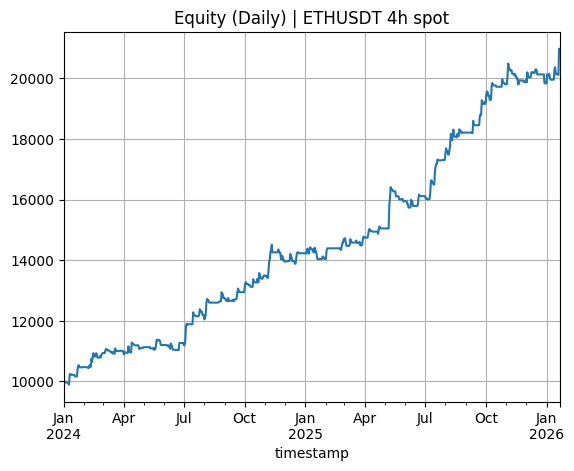

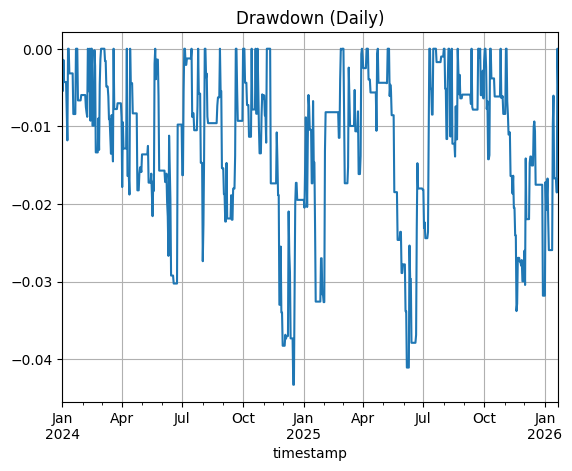

,entry_time,exit_time,side,entry,exit,qty,pnl_net,ret_on_eq,hold_bars
0,2024-01-02 04:00:00+00:00,2024-01-02 08:00:00+00:00,1,2385.84,2391.24,2.011325,10.861156,0.001086,1
1,2024-01-02 08:00:00+00:00,2024-01-02 12:00:00+00:00,1,2391.24,2357.48,1.938064,-65.429032,-0.006536,1
2,2024-01-03 12:00:00+00:00,2024-01-03 16:00:00+00:00,-1,2240.39,2206.53,1.308765,44.314780,0.004456,1
3,2024-01-03 16:00:00+00:00,2024-01-03 20:00:00+00:00,-1,2206.54,2209.72,1.302350,-4.141473,-0.000415,1
4,2024-01-03 20:00:00+00:00,2024-01-04 00:00:00+00:00,-1,2209.72,2231.08,1.338256,-28.585139,-0.002863,1
5,2024-01-08 16:00:00+00:00,2024-01-08 20:00:00+00:00,1,2354.57,2330.44,1.645865,-39.714726,-0.003989,1
6,2024-01-08 20:00:00+00:00,2024-01-09 00:00:00+00:00,1,2330.43,2309.13,1.662566,-35.412656,-0.003571,1
7,2024-01-10 00:00:00+00:00,2024-01-10 04:00:00+00:00,1,2361.50,2368.75,1.389954,10.077166,0.001020,1
8,2024-01-10 04:00:00+00:00,2024-01-10 08:00:00+00:00,1,2368.75,2402.21,1.417381,47.425582,0.004794,1
9,2024-01-10 08:00:00+00:00,2024-01-10 12:00:00+00:00,1,2402.21,2449.30,1.377989,64.889506,0.006529,1


In [ ]:
cfg = BTConfig(
    initial_equity=10_000,
    fee_rate=0,
    slippage_bps=0,
    leverage=1.0,
    risk_fraction=0.01,        # scale theo equity
    max_pos_fraction=1.0,
    sl_first_if_both_hit=False, # conservative -> tránh Sharpe ảo
    max_hold_bars=True
)

equity, trades, pos = run_backtest_tp_sl_touch(
    df=df,
    signal=signal,
    atr_for_entry=atr_for_entry,
    tp_atr_mult=2.5,
    sl_atr_mult=1.5,
    cfg=cfg
)

stats = compute_crypto_stats(equity, trades, pos)
print("=== STATS (Crypto-style: daily MTM) ===")
for k, v in stats.items():
    print(f"{k}: {v}")

# Plot equity
equity_daily = equity.resample("1D").last().dropna()
peak = equity_daily.cummax()
dd = equity_daily / peak - 1.0

plt.figure()
equity_daily.plot()
plt.title(f"Equity (Daily) | {SYMBOL} {INTERVAL} {MARKET}")
plt.grid(True)
plt.show()

plt.figure()
dd.plot()
plt.title("Drawdown (Daily)")
plt.grid(True)
plt.show()

trades.head(10)
